<div class="alert alert-info">
<h1>Beyond the standard GLM</h1>
<h4>Homework to Environmental Statistics 4</h4>
    
Your Names in Here!
</div>

This weeks exercises will practice the content of the lecture and tutorials and *extend* them in different ways:
 
  * fit a non-linear function to data;
  * explore solutions off the beaten track for GLM-like regression.
  

# Exercise 1 (14 points): Non-linear fish growth
Fish growth is a crucial element of stock assessments, and hence an applied biometrical activity for decades. One common function used to describe growth (such as length) over time is the [van Bertalanffy growth function](https://en.wikipedia.org/wiki/Von_Bertalanffy_function): $L(t) = L_\infty (1-e^{-k(t-t_0)})$. In this exercise, you will fit this function to data on walleye growth (*Sander vitreus*, Germ.: *Glasaugenbarsch, Amerikanischer Zander*), sampled in lake Erie.

  * Load and plot the data of walleye length (`tl`) over `age` (**FSAdata**'s `WalleyeErie2`). (**1 point**)
  * Write a function to represent the van Bertalanffy growth function (as given above). The first argument is age, the second the three parameters of the function. Plot this function (e.g. using `curve`) with the parameters $L_\infty=700, k=0.3$ and $t_0-1$. Play with the parameters: which aspect of the curve do they affect? (**2 points**)
  * Write the target function for optimisation, which internally calls the van Bertalanffy growth function you have written in the previous step. Assume the data are normally distributed. Test it for the values `(700, 0.2, 0, 2)` (for $L_\infty$, $k$, $t_0$ and $\sigma$, respectively). (If the value is not $-10017945$, then you or I have done something wrong.) (**2 points**)
  * Find optimal parameters for the growth function and the walleye data. Note that estimates for this function are not very stable. Use the following starting values: ($650, 0.36, -1, 2$). As method, use a quasi-Newton approach, such as BFGS, not the default Nelder-Mead [In principle it shouldn't matter, but when the estimates are fickle, it does. You can also try other robust optimisers, such as simulated annealing, if you want. The best fit has the highest log-likelihood, no matter which optimiser you used]. 
  Remember that the optimiser should report convergence (in R: `convergence 0`, in Python: `message: Optimization terminated successfully` and `success: True`). Change settings such as maximal number of iterations if it does not converge. (**3 points**)
  * Now split the data set by sex. Fit the growth function to each sex separately. Use the overall optimal parameters as starting values! [For some reason, the Nelder-Mead method worked better now than the quasi-Newtonian approaches. Again, play with the optimisers until you found the highest log-likelihood]. (**3 points**)
  * Plot the data using density clouds (e.g. `smoothScatter`) and add the three lines (overall, female, male). Colour data points by sex to better eyeball the fit of the curves. (**2 points**)
  * Optimisation is always a hairy business. One (among many) problems is that two parameters are highly (negatively) correlated, so that the data can be fitted by different combinations of these two parameters ("equifinality"). One way to check that is to look at the Hessian matrix of the optimiser, after converting it to a correlation matrix (i.e. standardising it using `cov2cor`)[Remember that the Hessian needs to be multiplied with -1 if you used the negative log-likelihood as optimisation target]. So, taking the male walleye in this data set, are ther problematic levels of correlation among the parameters? (**1 point**)
  
### 1.1 Load and plot

In [1]:
# Call the necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
import statsmodels.othermod.betareg as betareg
from statsmodels.othermod.betareg import BetaModel
from statsmodels.genmod import families
links = families.links
import statsmodels.api as sm
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
from pygam import LogisticGAM, LinearGAM


In [2]:
WalleyeErie2 = pd.read_csv("X:/Mitarbeiter_innen/Ikedichi/ik1015/Ikedichi_Python/WalleyeErie2.csv")
WalleyeErie2.describe()

,setID,loc,grid,year,tl,w,age
count,3.373400e+04,33734.000000,33734.000000,33734.000000,33734.000000,33321.00000,33734.000000
mean,2.008654e+06,1.812770,1059.724403,2008.591036,457.667013,1087.83863,3.152013
std,2.925555e+03,0.603045,127.082614,2.893990,80.693440,650.73655,2.244731
min,2.003001e+06,1.000000,880.000000,2003.000000,222.000000,104.00000,0.000000
25%,2.006041e+06,1.000000,987.000000,2006.000000,395.000000,587.00000,2.000000
50%,2.009017e+06,2.000000,1031.000000,2009.000000,456.000000,953.00000,3.000000
75%,2.011029e+06,2.000000,1101.000000,2011.000000,512.000000,1429.00000,4.000000
max,2.014054e+06,3.000000,1440.000000,2014.000000,778.000000,5186.00000,20.000000


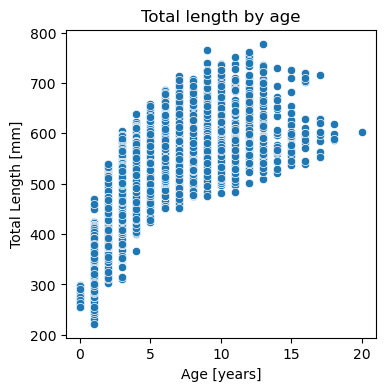

In [3]:
# Now the plot
plt.figure(figsize=(4,4))
sns.scatterplot(x="age",
                y="tl",
                data=WalleyeErie2)
plt.xlabel('Age [years]')
plt.ylabel('Total Length [mm]')
plt.title('Total length by age')
plt.show()

## 1.2 Plot the van Bertalanffy growth function


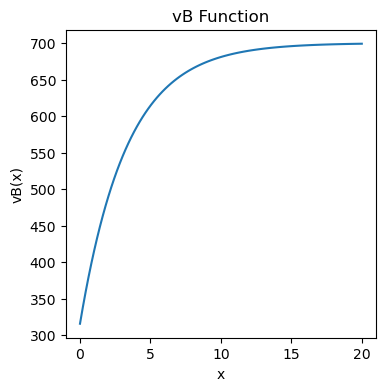

In [3]:
# Define the vB function
def vB(x, par=[700, 0.3, -2]):  # growth funcion, according to van Bertalanffy
    Linf, k, t0 = par  # Linf: maximal size, k: growth rate, t0: since length at hatching >0: t0 < 0
    return Linf * (1 - np.exp(-k * (x - t0)))

# Generate x values
x = np.linspace(0, 20, 100)  # Generate 100 points between 0 and 20

# Calculate y values using vB function
y = vB(x)

# Create the plot
plt.figure(figsize=(4,4))
plt.plot(x, y)
plt.xlabel('x')
plt.ylabel('vB(x)')
plt.title('vB Function')
plt.grid(False)
plt.show()


$L_\infty$ is the asymptote of growth; $k$ the growth rate, i.e how fast over time that asymptote is reached; $t_0$ is the hypothetical time at which the curve would hit the x-axis. Since fish emerge with a certain size, the observed length is always > 0, hence $t_0$ is negative.

### 1.3 Optimisation function

In [20]:
def ellvB(par):
    mean = vB(WalleyeErie2.age, par[:3])
    sd = np.exp(par[3])
    log_likelihood = np.sum(norm.logpdf(WalleyeErie2.tl, loc=mean, scale=sd))
    return log_likelihood

# Test the function with given parameter vector
result = ellvB([700, 0.2, 0, 2])

print(result)

-10017944.66444973


### 1.4 Optimise vBGF

In [34]:
# Define initial parameter guess
initial_guess = [650, 0.36, -1, 2]

# Define a wrapper function for ellvB that takes a single argument as required by minimize
def ellvB_wrapper(par):
    return -ellvB(par)  

# Optimize the function
op = minimize(ellvB_wrapper, initial_guess, method='Powell',  #BFGS, Nelder-Mead, Powell, CG, L-BFGS-B, COBYLA, SLSQP
                  options={'maxiter': 1000})


Linf_opt, k_opt, t0_opt, log_s_opt = op.x

# Extract the optimized parameters
print("Optimized Parameters:")
print("a:", Linf_opt)
print("b:", k_opt)
print("c:", t0_opt)
print("s:", log_s_opt)
print("")
print("Negative Log-Likelihood:", -op.fun)
print("Convergence Message:", op.message)

Optimized Parameters:
a: 580.6368090228511
b: 0.4142162551849785
c: -1.2890838982085495
s: 3.637093284489203

Negative Log-Likelihood: -170573.48527629755
Convergence Message: Optimization terminated successfully.


## 1.5 Now split the data set by sex. Fit the growth function to each sex separately.

In [36]:
female = WalleyeErie2[WalleyeErie2['sex']=="female"]
male = WalleyeErie2[WalleyeErie2['sex']=="male"]


def ellvBfemale(par):
    mean = vB(female.age, par[:3])
    sd = np.exp(par[3])
    log_likelihood = np.sum(norm.logpdf(female.tl, loc=mean, scale=sd))
    return log_likelihood

def ellvBmale(par):
    mean = vB(male.age, par[:3])
    sd = np.exp(par[3])
    log_likelihood = np.sum(norm.logpdf(male.tl, loc=mean, scale=sd))
    return log_likelihood

result_female = ellvBfemale([600, 0.4, -1, 4])
result_male = ellvBmale([600, 0.4, -1, 4])

print("Female log-likelihood:", result_female)
print("Male log-likelihood:", result_male)

Female log-likelihood: -70066.97901322079
Male log-likelihood: -105328.04848563051


In [40]:
## optimise female

initial_guess = [633, 0.27, -2, 3.6]

def ellvB_wrapper(par):
    return -ellvBfemale(par)  

# Optimize the function
opfemale = minimize(ellvB_wrapper, initial_guess, method='Nelder-Mead',
                  options={'maxiter': 5000}) #, 'xatol': 1e-8, 'disp': True


Linf_opt, k_opt, t0_opt, log_s_opt = opfemale.x

# Extract the optimized parameters
print("Optimized Parameters:")
print("a:", Linf_opt)
print("b:", k_opt)
print("c:", t0_opt)
print("s:", log_s_opt)
print("")
print("Negative Log-Likelihood:", -opfemale.fun)
print("Convergence Message:", opfemale.message)


Optimized Parameters:
a: 675.8023840276514
b: 0.31719720297845777
c: -1.4012135258063758
s: 3.4399042014521006

Negative Log-Likelihood: -64574.01676964974
Convergence Message: Optimization terminated successfully.


In [39]:
## optimise male

initial_guess = [633, 0.27, -2, 3.6]

def ellvB_wrapper(par):
    return -ellvBmale(par)  # Note the negative sign because we're minimizing

# Optimize the function
opmale = minimize(ellvB_wrapper, initial_guess, method='Nelder-Mead',
                  options={'maxiter': 5000})

Linf_opt, k_opt, t0_opt, log_s_opt = opmale.x

# Extract the optimized parameters
print("Optimized Parameters:")
print("a:", Linf_opt)
print("b:", k_opt)
print("c:", t0_opt)
print("s:", log_s_opt)
print("")
print("Negative Log-Likelihood:", -opmale.fun)
print("Convergence Message:", opmale.message)


Optimized Parameters:
a: 568.2560665607884
b: 0.3379129988927806
c: -1.9335183511588432
s: 3.3564153101117435

Negative Log-Likelihood: -97627.33111763696
Convergence Message: Optimization terminated successfully.


#### In case somebody stumbles on the `differential_evolution()` function from the `scipy.optimize` module:

In [10]:

# Define bounds for parameters
bounds = [(200, 700), (0, 1), (-10, 0), (0, 10)]

# Define the objective function (negated)
def objective_function(params):
    return -ellvBmale(params)

# Perform differential evolution optimization
result = differential_evolution(objective_function, bounds, maxiter=500, disp=False)

# Print the summary
print("Optimization result:")
print("  Message:", result.message)
print("  Number of evaluations:", result.nfev)
print("  Final parameters:", result.x)
print("  Final log-likelihood:", -result.fun)  # practically same as opmale above!

Optimization result:
  Message: Optimization terminated successfully.
  Number of evaluations: 1500
  Final parameters: [ 5.68256485e+02  3.37911297e-01 -1.93353030e+00  3.35641794e+00]
  Final log-likelihood: -97627.33111791233


### 1.6 Nice plot

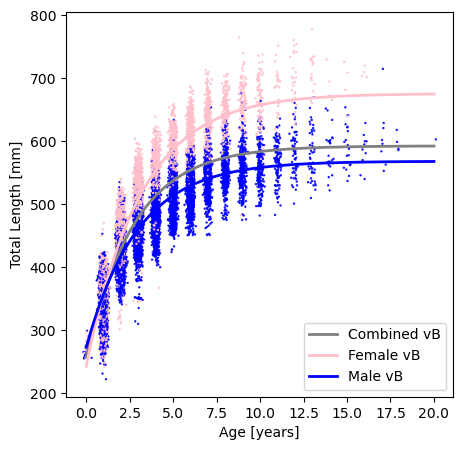

In [12]:
# Scatter plot
plt.figure(figsize=(5, 5))
plt.scatter(np.random.normal(WalleyeErie2['age'], 0.1), WalleyeErie2['tl'], 
            c=np.where(WalleyeErie2['sex'] == 'female', 'pink', 'blue'), alpha=0.9, marker='.', s=2)
plt.xlabel('Age [years]')
plt.ylabel('Total Length [mm]')

# Define x values for the vB curves
x_values = np.linspace(min(WalleyeErie2['age']), max(WalleyeErie2['age']), 100)

# Plot vB curves
plt.plot(x_values, vB(x_values, op.x[:3]), lw=2, color='grey', label='Combined vB')
plt.plot(x_values, vB(x_values, opfemale.x[:3]), lw=2, color='pink', label='Female vB')
plt.plot(x_values, vB(x_values, opmale.x[:3]), lw=2, color='blue', label='Male vB')


plt.legend()
plt.show()

### 1.7 Correlation among parameters fitted

In [13]:
## optimise male

initial_guess = [633, 0.27, -2, 3.6]

def ellvB_wrapper(par):
    return -ellvBmale(par) 


# Optimize the function
result = minimize(ellvB_wrapper, initial_guess, method='BFGS', options={'maxiter': 1000})

# Get the Hessian matrix
hessian = result.hess_inv

# Calculate the correlation matrix
correlation_matrix = np.corrcoef(-hessian)

#print("Correlation matrix:")
print(correlation_matrix)

[[ 1.         -0.99957775 -0.88488645 -0.99917003]
 [-0.99957775  1.          0.89804703  0.99982271]
 [-0.88488645  0.89804703  1.          0.90146403]
 [-0.99917003  0.99982271  0.90146403  1.        ]]


Yes, all three parameter of the growth function are highly correlated, explaining the difficulty of the algorithm to find the same global solution when starting from different values.

# Exercise 2 (13 points): GLM with weird distribution by foot (and mgcv)
Sometimes we have to employ distributions unfamiliar to us, implemented in unfamiliar packages of unclear quality. That is something we have to live with, so let's practice it a bit. A common such case arises with proportions, i.e. data between 0 and 1 (or percentages, divided by 100).

The cover of blueberry (*Vaccinium myrtillus*) in pine forest in northern Sweden is somewhat affected by the thickness of the soil humus layer. **vegan**'s `varespec` data contain the cover data, `varechem` the humus depth information. 

  * Make a new variable of blueberry cover, by adding a small value (0.1) to all data points. This is needed because our methods requires all data to be *within* (0,1). Plot this new variable against humus depth. (**2 points**)
  * Fit three regressions:
  
    * an ordinary linear model (**1 point**);
    * a beta-regression (offered by **betareg**' `betareg`; **1 point**); 
    * another beta-regression (offered by **mgcv**'s family option `betar`; **2 points**).
    * Do parameter estimates differ? (**1 point**)
  
  * Plot the three fitted models, including 95% confidence interval, into a "production-level" plot. (**4 points**)
  * Interpret the results, and the difference between lines, and the difference between 95% confidence intervals. Which of the two beta-regression models is "correcter"? How can you tell? (**2 points**)
  
### Load, prepare and plot data  

In [43]:
vareche = pd.read_csv("X:/Mitarbeiter_innen/Ikedichi/ik1015/Ikedichi_Python/varechem.csv")
varespe = pd.read_csv("X:/Mitarbeiter_innen/Ikedichi/ik1015/Ikedichi_Python/varespec.csv")

varespec = varespe.copy() 
varespec.drop(columns=varespec.columns[0], axis=1, inplace=True) # drop first column
varespec.index = varespe['Unnamed: 0']    # replace the index
varespec.describe()

,Callvulg,Empenigr,Rhodtome,Vaccmyrt,Vaccviti,Pinusylv,Descflex,Betupube,Vacculig,Diphcomp,...,Cetreric,Cetrisla,Flavniva,Nepharct,Stersp,Peltapht,Icmaeric,Cladcerv,Claddefo,Cladphyl
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,...,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,1.877917,6.332917,0.349583,2.112917,11.459583,0.171250,0.233333,0.012083,0.634167,0.135000,...,0.150000,0.084583,0.493750,0.219167,0.730000,0.031667,0.009167,0.004167,0.426250,0.033333
std,4.987779,4.772715,0.965791,4.818508,6.230435,0.274041,0.763776,0.050988,1.703694,0.429772,...,0.209097,0.155059,2.037014,0.991867,2.079576,0.082865,0.024833,0.012129,0.509448,0.084270
min,0.000000,0.130000,0.000000,0.000000,1.980000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.832500,0.000000,0.000000,6.672500,0.030000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.095000,0.000000
50%,0.075000,5.700000,0.000000,0.000000,11.250000,0.100000,0.000000,0.000000,0.000000,0.000000,...,0.050000,0.020000,0.000000,0.000000,0.065000,0.000000,0.000000,0.000000,0.250000,0.000000
75%,1.095000,9.725000,0.000000,0.800000,14.547500,0.152500,0.050000,0.000000,0.267500,0.017500,...,0.197500,0.090000,0.127500,0.000000,0.677500,0.005000,0.000000,0.000000,0.417500,0.000000
max,24.130000,16.000000,4.000000,18.270000,25.000000,1.200000,3.700000,0.250000,8.100000,2.070000,...,0.780000,0.670000,10.030000,4.870000,10.280000,0.330000,0.100000,0.050000,1.970000,0.250000


In [44]:
varechem = vareche.copy() 
varechem.drop(columns=varechem.columns[0], axis=1, inplace=True) # drop first column
varechem.index = vareche['Unnamed: 0']    # replace the index
varechem

varechem.describe()

,N,P,K,Ca,Mg,S,Al,Fe,Mn,Zn,Mo,Baresoil,Humdepth,pH
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,22.383333,45.079167,162.929167,569.662500,87.458333,37.191667,142.475000,49.612500,49.329167,7.595833,0.395833,22.949167,2.200000,2.933333
std,5.528084,14.946396,64.842361,243.581962,41.011344,11.667827,122.320389,60.448896,33.911336,2.983939,0.239980,16.439445,0.664635,0.214003
min,13.400000,22.700000,43.600000,188.500000,25.700000,14.900000,12.100000,2.300000,10.100000,2.600000,0.050000,0.010000,1.000000,2.700000
25%,18.825000,32.600000,127.150000,425.725000,60.900000,29.425000,38.200000,5.575000,26.700000,5.375000,0.275000,7.975000,1.800000,2.800000
50%,22.050000,41.500000,166.600000,518.500000,75.050000,36.250000,106.800000,27.800000,36.550000,8.100000,0.300000,21.250000,2.200000,2.900000
75%,26.300000,57.050000,205.750000,739.250000,108.700000,43.600000,233.725000,85.150000,59.000000,9.100000,0.500000,30.750000,2.625000,3.000000
max,33.100000,73.500000,313.800000,1169.700000,209.100000,60.200000,435.100000,204.400000,132.000000,16.800000,1.100000,56.900000,3.800000,3.600000


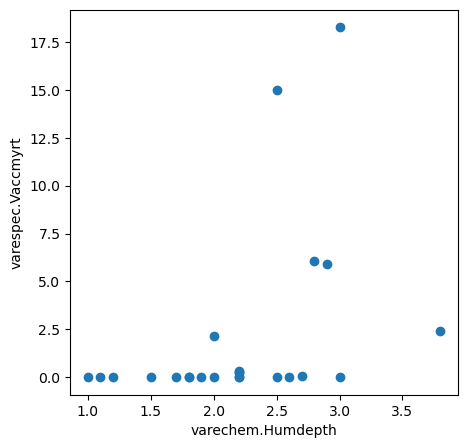

In [45]:
Vamy = (varespec.Vaccmyrt + 0.1)/100    # approx half lowest non-0 value

plt.figure(figsize=(5, 5))
plt.scatter(varechem.Humdepth, varespec.Vaccmyrt)
plt.xlabel('varechem.Humdepth')
plt.ylabel('varespec.Vaccmyrt')
plt.show()


# 2.2 Fit 3 models
### 2.2.1 The linear model

In [46]:
# Define the formula
X = varechem['Humdepth']
y = Vamy

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit logistic regression model
fm1 = sm.GLM(y, X, family=sm.families.Gaussian()).fit()

# Print the summary of the model
print(fm1.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Vaccmyrt   No. Observations:                   24
Model:                            GLM   Df Residuals:                       22
Model Family:                Gaussian   Df Model:                            1
Link Function:               Identity   Scale:                       0.0020146
Method:                          IRLS   Log-Likelihood:                 41.477
Date:                Fri, 17 Nov 2023   Deviance:                     0.044322
Time:                        12:42:59   Pearson chi2:                   0.0443
No. Iterations:                     3   Pseudo R-squ. (CS):             0.1742
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0436      0.032     -1.351      0.1

In [47]:
## OR

varechem['Vamy'] = Vamy

fm11 = ols('Vamy ~ Humdepth', data=varechem).fit()
print(fm11.summary())

                            OLS Regression Results                            
Dep. Variable:                   Vamy   R-squared:                       0.170
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     4.507
Date:                Fri, 17 Nov 2023   Prob (F-statistic):             0.0453
Time:                        12:43:01   Log-Likelihood:                 41.477
No. Observations:                  24   AIC:                            -78.95
Df Residuals:                      22   BIC:                            -76.60
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0436      0.032     -1.351      0.1

### 2.2.2 The beta-regression with betareg
The default cov_type in statsmodels is based on the observed hessian. `R` betareg uses by default the expected hessian. We can replicate this by specifying `cov_type="eim"` in the call to the fit method.

In [48]:
# Perform beta regression
model = "Vamy ~ Humdepth"
fm2 = BetaModel.from_formula(model, varechem, link_precision=links.identity()).fit(cov_type="eim")

print(fm2.summary())


C:\Users\Ikedichi_Azuh\anaconda3\envs\envstats\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The identity link alias is deprecated. Use Identity instead. The identity link alias will be removed after the 0.15.0 release.
  warnings.warn(


                              BetaModel Results                               
Dep. Variable:                   Vamy   Log-Likelihood:                 82.596
Model:                      BetaModel   AIC:                            -159.2
Method:            Maximum Likelihood   BIC:                            -155.7
Date:                Fri, 17 Nov 2023                                         
Time:                        12:43:05                                         
No. Observations:                  24                                         
Df Residuals:                      21                                         
Df Model:                           1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.1267      0.776     -6.605      0.000      -6.648      -3.605
Humdepth       0.5876      0.293      2.007      0.0

### 2.2.3 The beta-regression with pyGAM
For python, beta regression is not yet supported in GAM from pygam

### 2.2.4 Do parameter estimates differ?
Yes, the parameter estimates between beta-regression and the LM differ.

## 2.3 Plot fits (without CIs)

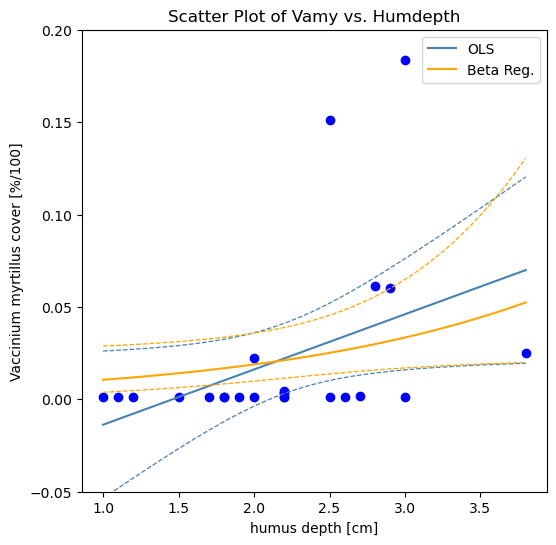

In [49]:
Vamy = (varespec.Vaccmyrt + 0.1)/100    # approx half lowest non-0 value

plt.figure(figsize=(6, 6))
plt.scatter(varechem['Humdepth'], Vamy, marker='o', color='blue')
plt.xlabel('humus depth [cm]')
plt.ylabel('Vaccinium myrtillus cover [%/100]')
plt.ylim(0,0.2)
plt.title('Scatter Plot of Vamy vs. Humdepth')
plt.grid(False)

newHum = pd.DataFrame(np.linspace(1, 3.8, 100), columns=["Humdepth"])

# OLS 
preds1 = fm11.get_prediction(newHum).summary_frame(alpha=0.05)

plt.plot(newHum, preds1['mean'], color='steelblue', label= "OLS")
plt.plot(newHum, preds1['mean_ci_upper'], color='steelblue',linestyle='--',linewidth=0.9)
plt.plot(newHum, preds1['mean_ci_lower'], color='steelblue',linestyle='--',linewidth=0.9)


# Beta reg
preds2 = fm2.get_prediction(newHum).summary_frame(alpha=0.05)

plt.plot(newHum, preds2['predicted'], color='orange', label= "Beta Reg.")
plt.plot(newHum, preds2['ci_upper'], color='orange',linestyle='--',linewidth=0.9)
plt.plot(newHum, preds2['ci_lower'], color='orange',linestyle='--',linewidth=0.9)

plt.legend()
plt.ylim(-0.05, 0.2)
plt.show()


The linear model is different from the beta-regressions. It is inadequate, as it goes below 0, yet its 95% confidence interval is wide and includes the beta-regression.